In [1]:
import os
import torch

# --- ローカルGPUの設定 ---
# あなたのPCに搭載されているGPU（通常は1台）をPyTorchから見えるように設定します。
# '0' を指定することで、最初の（そして多くの場合唯一の）GPUが選択されます。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

# --- 確認のためのコード ---
if torch.cuda.is_available():
    print("✅ ローカルGPUが利用可能です。")
    print(f"PyTorchが見ているデバイス数: {torch.cuda.device_count()}")
    print(f"現在のデバイス (PyTorch Index): {torch.cuda.current_device()}")
    print(f"デバイス名: {torch.cuda.get_device_name(0)}")
else:
    print("❌ GPUが利用できません。PyTorchのインストールを確認してください。")

✅ ローカルGPUが利用可能です。
PyTorchが見ているデバイス数: 1
現在のデバイス (PyTorch Index): 0
デバイス名: NVIDIA TITAN X (Pascal)


In [2]:
import pandas as pd
import nibabel as nib
import torch
from torch.utils.data import Dataset
from torchvision import transforms
import os

class BrainMetsDataset(Dataset):
    """
    【完成版】
    脳転移の時系列MRIデータセットのためのカスタムデータセットクラス。
    正しい正規化処理を適用し、「ベースライン画像」と「将来画像」のペアをAIに提供する。
    """
    def __init__(self, csv_file, image_root_dir, patient_ids, mode, image_size=256):
        self.data = pd.read_csv(csv_file)
        # 指定された患者IDのデータのみに絞り込む
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        
        self.image_root_dir = image_root_dir
        self.mode = mode # 'train', 'val', or 'test'
        self.pairs = self._create_pairs()
        
        # 画像の前処理を定義
        self.transform = transforms.Compose([
            transforms.ToTensor(), # 0-1範囲のデータをTensorに変換
            transforms.Resize((image_size, image_size), antialias=True),
            transforms.Normalize([0.5], [0.5]) # 0-1範囲のデータを-1から1の範囲に正規化
        ])

    def _create_pairs(self):
        pairs = []
        for patient_id, group in self.data.groupby('PatientID'):
            baseline_scans = group[group['FinalPattern'] == 'Baseline']
            future_scans = group[group['FinalPattern'] != 'Baseline']
            
            if baseline_scans.empty or future_scans.empty:
                continue

            for _, baseline_row in baseline_scans.iterrows():
                for _, future_row in future_scans.iterrows():
                    pairs.append({
                        "baseline_file": baseline_row['FileName'],
                        "future_file": future_row['FileName'],
                        "condition": future_row['FinalPattern']
                    })
        print(f"Found {len(pairs)} pairs for '{self.mode}' set.")
        return pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]
        
        try:
            # --- 1. 両方の画像のパスを正しく作成 ---
            base_name_without_ext = pair['baseline_file'].replace('.nii.gz', '')
            baseline_filename = f"{base_name_without_ext}_0000.nii.gz"
            baseline_path = os.path.join(self.image_root_dir, baseline_filename)

            future_name_without_ext = pair['future_file'].replace('.nii.gz', '')
            future_filename = f"{future_name_without_ext}_0000.nii.gz"
            future_path = os.path.join(self.image_root_dir, future_filename)
            
            # --- 2. 両方のMRI画像を読み込み、中央スライスを抽出 ---
            baseline_nii = nib.load(baseline_path)
            future_nii = nib.load(future_path)
            
            baseline_slice = baseline_nii.get_fdata().astype('float32')[:, :, baseline_nii.shape[2] // 2]
            future_slice = future_nii.get_fdata().astype('float32')[:, :, future_nii.shape[2] // 2]

            # --- 3. ★★★ ここが最重要の修正点 ★★★ ---
            # 両方のスライスに対して、個別に0から1の範囲に正規化
            if baseline_slice.max() > baseline_slice.min():
                baseline_slice = (baseline_slice - baseline_slice.min()) / (baseline_slice.max() - baseline_slice.min())
            
            if future_slice.max() > future_slice.min():
                future_slice = (future_slice - future_slice.min()) / (future_slice.max() - future_slice.min())
            
            # --- 4. PyTorchのtransformを適用 ---
            baseline_image = self.transform(baseline_slice)
            future_image = self.transform(future_slice)
            
            # --- 5. 3チャンネルに拡張 ---
            baseline_image = baseline_image.repeat(3, 1, 1)
            future_image = future_image.repeat(3, 1, 1)

            # --- 6. 辞書形式で全てのデータを返す ---
            return {
                "baseline_image": baseline_image,
                "future_image": future_image,
                "condition_label": pair['condition']
            }

        except FileNotFoundError as e:
            # 万が一ファイルが見つからなかった場合、学習を止めずに次のデータを試す
            print(f"Warning: File not found ({e}). Skipping this pair.")
            return self.__getitem__((idx + 1) % len(self))

In [3]:
import torch
import torch.nn as nn
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, ControlNetModel

# ===================================================================
# 【Final and Corrected】CustomConditionalLDM Class Definition
# ===================================================================
class CustomConditionalLDM(nn.Module):
    def __init__(self, pretrained_model_name="runwayml/stable-diffusion-v1-5"):
        super().__init__()
        
        self.vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae")
        self.tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
        self.text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder")
        self.unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet")
        self.scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
        self.controlnet = ControlNetModel.from_config(self.unet.config)
        
        # ★★★ The Final, Crucial Fix ★★★
        # Replace the default conditioning embedding with a simple one that matches the shapes.
        # This ensures the "highway" and the "on-ramp" have the same number of lanes.
        in_channels = 4 # VAE latent has 4 channels
        out_channels = self.controlnet.conv_in.out_channels # Match the main U-Net input channels (e.g., 320)
        
        self.controlnet.controlnet_cond_embedding = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        )
        # Initialize the new part with zeros for stable training (Zero Convolution)
        for module in self.controlnet.controlnet_cond_embedding.modules():
            if isinstance(module, nn.Conv2d):
                torch.nn.init.zeros_(module.weight)
                torch.nn.init.zeros_(module.bias)

        # Freeze the parts we are not training
        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.unet.requires_grad_(False)
        
        print("✅ CustomConditionalLDM model initialized with FINAL architecture.")
        print("   - VAE, Text Encoder, and U-Net are FROZEN.")
        print("   - Only the ControlNet is TRAINABLE.")

    def forward(self, batch):
        # ... (the forward function does not need to change) ...
        baseline_images = batch["baseline_image"]
        future_images = batch["future_image"]
        condition_labels = batch["condition_label"]

        with torch.no_grad():
            baseline_latents = self.vae.encode(baseline_images).latent_dist.sample() * self.vae.config.scaling_factor
            future_latents = self.vae.encode(future_images).latent_dist.sample() * self.vae.config.scaling_factor
            
        noise = torch.randn_like(future_latents)
        timesteps = torch.randint(0, self.scheduler.config.num_train_timesteps, (future_latents.shape[0],), device=future_latents.device).long()
        noisy_future_latents = self.scheduler.add_noise(future_latents, noise, timesteps)

        with torch.no_grad():
            text_input = self.tokenizer(condition_labels, padding="max_length", max_length=self.tokenizer.model_max_length, truncation=True, return_tensors="pt")
            text_embeddings = self.text_encoder(text_input.input_ids.to(self.unet.device))[0]

        down_block_res_samples, mid_block_res_sample = self.controlnet(
            noisy_future_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            controlnet_cond=baseline_latents,
            return_dict=False,
        )

        predicted_noise = self.unet(
            noisy_future_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            down_block_additional_residuals=down_block_res_samples,
            mid_block_additional_residual=mid_block_res_sample
        ).sample

        return predicted_noise, noise

/home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/accelerate/utils/torch_xla.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
from sklearn.model_selection import train_test_split
import pandas as pd

# CSVを読み込んで、ユニークな患者IDのリストを取得
csv_path = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(csv_path)
patient_ids = full_df['PatientID'].unique()

# ステップ1: まず学習用(70%)と、残り(30%)に分割
train_patient_ids, temp_patient_ids = train_test_split(
    patient_ids, test_size=0.3, random_state=42
)

# ステップ2: 残り(30%)を、検証用(15%)とテスト用(15%)に半分ずつ分割
val_patient_ids, test_patient_ids = train_test_split(
    temp_patient_ids, test_size=0.5, random_state=42
)

print(f"Total patients: {len(patient_ids)}")
print(f"Training patients: {len(train_patient_ids)}")
print(f"Validation patients: {len(val_patient_ids)}")
print(f"Test patients: {len(test_patient_ids)}")

# test_patient_idsは後で使うので、内容を確認（しなくてもOK）
# print("\nTest Set Patient IDs:", test_patient_ids)

Total patients: 1362
Training patients: 953
Validation patients: 204
Test patients: 205


In [5]:
#モデル構築と検証のセル
import torch

# --- 1. デバイスの設定 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. モデルのインスタンス化 ---
try:
    print("\nInitializing the model...")
    print("(Hugging Faceから学習済みモデルをダウンロードするため、初回は数分かかります)")
    model = CustomConditionalLDM().to(device)
    print("✅ Model created successfully and moved to device!")

    # --- 3. 学習可能なパラメータ数の計算と表示 ---
    num_params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    num_params_total = sum(p.numel() for p in model.parameters())

    print("\n--- Model Parameter Analysis ---")
    print(f"Total parameters: {num_params_total / 1e6:.2f} M")
    print(f"Trainable parameters: {num_params_trainable / 1e6:.2f} M")
    if num_params_total > 0:
        print(f"Trainable parameter percentage: {100 * num_params_trainable / num_params_total:.2f}%")

except Exception as e:
    print(f"❌ An error occurred during model initialization: {e}")

Using device: cuda

Initializing the model...
(Hugging Faceから学習済みモデルをダウンロードするため、初回は数分かかります)
✅ CustomConditionalLDM model initialized with FINAL architecture.
   - VAE, Text Encoder, and U-Net are FROZEN.
   - Only the ControlNet is TRAINABLE.
✅ Model created successfully and moved to device!

--- Model Parameter Analysis ---
Total parameters: 1427.36 M
Trainable parameters: 361.13 M
Trainable parameter percentage: 25.30%


Found 5461 pairs for 'train' set.
Found 1082 pairs for 'val' set.
Found 1091 pairs for 'test' set.

🔥 Starting training! 🔥


Epoch 1 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/541 [00:00<?, ?it/s]

Epoch 1/150 | Train Loss: 0.0716 | Val Loss: 0.0721
🏆 New best model saved to /home/masaki/mystudy/trained_models/best_model_epoch_1.pth (Val Loss: 0.0721)


Epoch 2 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 2 [Val]:   0%|          | 0/541 [00:00<?, ?it/s]

... (441 outputs left out)

Epoch 149/150 | Train Loss: 0.0622 | Val Loss: 0.0637


Epoch 150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 150 [Val]:   0%|          | 0/541 [00:00<?, ?it/s]

Epoch 150/150 | Train Loss: 0.0626 | Val Loss: 0.0648


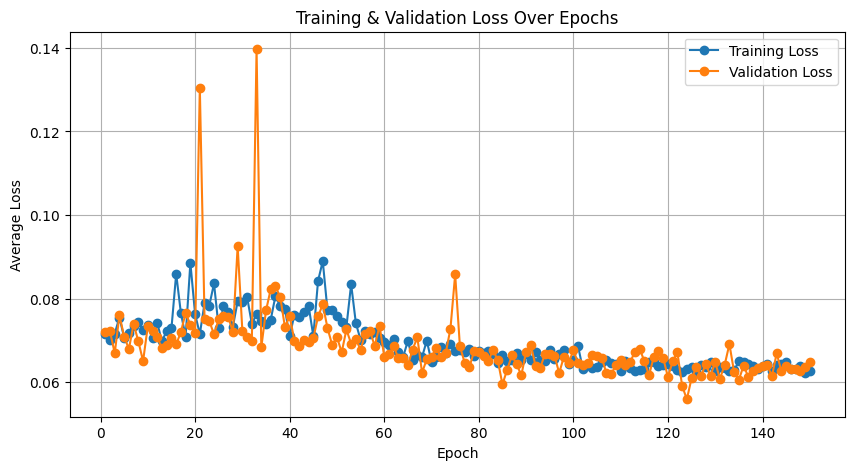

In [6]:
# ===================================================================
# アクション4：学習プロセスの実装（最終版）
# ===================================================================

# --- 0. 必要なライブラリを全てインポート ---
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from diffusers.optimization import get_cosine_schedule_with_warmup
from tqdm.auto import tqdm
import os
import matplotlib.pyplot as plt

# --- 1. ハイパーパラメータ ---
LEARNING_RATE = 1e-4
BATCH_SIZE = 2
NUM_EPOCHS = 150
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
OUTPUT_DIR = "/home/masaki/mystudy/trained_models"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- 2. データローダーの準備 (学習用、検証用、テスト用に分ける) ---
# (このセルを実行する前に、データ分割のセルが実行されている必要があります)
train_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=train_patient_ids, mode='train')
val_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=val_patient_ids, mode='val')
test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# --- 3. モデル、オプティマイザ、スケジューラ ---
# (このセルを実行する前に、モデル構築のセルが実行されている必要があります)
optimizer = torch.optim.AdamW(model.controlnet.parameters(), lr=LEARNING_RATE)
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer=optimizer, num_warmup_steps=500, num_training_steps=(len(train_dataloader) * NUM_EPOCHS)
)

# --- 4. 学習ループ (検証ループ付き) ---
train_losses = []
val_losses = []
best_val_loss = float('inf')

print("\n🔥 Starting training! 🔥")
for epoch in range(NUM_EPOCHS):
    # --- 学習フェーズ ---
    model.train()
    train_step_losses = []
    train_progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch + 1} [Train]")
    for batch in train_progress_bar:
        batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}
        predicted_noise, actual_noise = model(batch)
        loss = F.mse_loss(predicted_noise, actual_noise)
        
        train_step_losses.append(loss.item())
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        train_progress_bar.set_postfix(loss=loss.item())
    
    avg_train_loss = sum(train_step_losses) / len(train_step_losses)
    train_losses.append(avg_train_loss)

    # --- 検証フェーズ ---
    model.eval()
    val_step_losses = []
    val_progress_bar = tqdm(val_dataloader, desc=f"Epoch {epoch + 1} [Val]")
    with torch.no_grad():
        for batch in val_progress_bar:
            batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}
            predicted_noise, actual_noise = model(batch)
            loss = F.mse_loss(predicted_noise, actual_noise)
            val_step_losses.append(loss.item())
            val_progress_bar.set_postfix(loss=loss.item())

    avg_val_loss = sum(val_step_losses) / len(val_step_losses)
    val_losses.append(avg_val_loss)
    
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    # 検証ロスが過去最高なら、ベストモデルとして保存
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        save_path = os.path.join(OUTPUT_DIR, f"best_model_epoch_{epoch+1}.pth")
        torch.save(model.controlnet.state_dict(), save_path)
        print(f"🏆 New best model saved to {save_path} (Val Loss: {best_val_loss:.4f})")

# --- 5. グラフ描画 (学習と検証の両方をプロット) ---
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, marker='o', label='Training Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, marker='o', label='Validation Loss')
plt.title("Training & Validation Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.legend()
plt.grid(True)
plt.show()